# 02 · Validación Visual del Fenotipo de Resiliencia Motora
**Ticket 2.2** · Módulo de Features: Software Motor y Target de Resiliencia

### Objetivo Clínico y Metodológico
En prematuros con bajo peso al nacer (<1801 g), dos individuos con un daño cerebral estructural similar (mismo nivel de *Hardware Motor*, $HW\_motor\_qc$) pueden exhibir desempeños funcionales notablemente divergentes en pruebas de destreza motora fina (*Software Motor*, $SW\_motor$).

Este notebook valida el fenotipo de **Resiliencia Motora**, definido operacionalmente a través de los residuales de un modelo lineal multivariado:

$$\text{SW\_motor}_i = \beta_0 + \beta_1 \cdot \text{hw\_motor\_qc}_i + \beta_2 \cdot \text{BIRTH\_sexo5}_i + \beta_3 \cdot \text{FOLLOW\_Fragility\_Rasch\_441\_2PL}_i + \epsilon_i$$

Donde:
- **$\text{SW\_motor}$**: Promedio del tiempo en prueba *Nine-Hole Peg Test* (NHPT) para ambas manos, estandarizado con Z-score robusto e invertido (mayor puntaje = mejor destreza/velocidad).
- **$\text{hw\_motor\_qc}$**: Índice de sustrato neuroanatómico ponderado (volúmenes de ganglios basales, corteza motora Brodmann M1/S1 y microestructura CST) filtrado por control estricto de movimiento en RM (DEC-019).
- **$\text{resilience\_score} = \epsilon_i$**: Residual del modelo. Un residual positivo ($> 0$) identifica a un sujeto **Resiliente** (`is_resilient = True`), cuyo rendimiento motor sobrepasa la expectativa dictada por su daño estructural y su fragilidad clínica.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LinearRegression

# Configuración estética de visualizaciones
sns.set_theme(style="whitegrid", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# Rutas del repositorio
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FEATURES_DIR = ROOT / "data" / "features"
TARGET_PATH = FEATURES_DIR / "target_resilience.parquet"
HW_PATH = FEATURES_DIR / "hw_motor.parquet"

print(f"Directorio raíz del proyecto: {ROOT}")
print(f"Target path: {TARGET_PATH}")
print(f"HW path: {HW_PATH}")

Directorio raíz del proyecto: C:\Users\mhgua\Documents\Andes\202621\Proyecto\ProyectoFinal-FundacionCanguro
Target path: C:\Users\mhgua\Documents\Andes\202621\Proyecto\ProyectoFinal-FundacionCanguro\data\features\target_resilience.parquet
HW path: C:\Users\mhgua\Documents\Andes\202621\Proyecto\ProyectoFinal-FundacionCanguro\data\features\hw_motor.parquet


## 1. Carga de Datos y Unión de Características (100% Datos Reales)
Cargamos directamente los archivos producidos por el pipeline orquestado (`target_resilience.parquet` y `hw_motor.parquet`) y realizamos el merge interno sobre la clave de identificación `code`.

In [2]:
if not TARGET_PATH.exists() or not HW_PATH.exists():
    raise FileNotFoundError(
        f"No se encontraron los archivos de features necesarios.\n"
        f"- Target path: {TARGET_PATH} ({'Existe' if TARGET_PATH.exists() else 'FALTA'})\n"
        f"- Hardware path: {HW_PATH} ({'Existe' if HW_PATH.exists() else 'FALTA'})\n"
        "Ejecuta el pipeline completo primero:\n"
        "  uv run python -m src.pipeline"
    )

target_df = pd.read_parquet(TARGET_PATH)
hw_df = pd.read_parquet(HW_PATH)

# Merge interno sobre 'code'
df_merged = pd.merge(target_df, hw_df[["code", "hw_motor_qc"]], on="code", how="inner")

print(f"Dataset combinado para validación: N = {len(df_merged)} pacientes reales")
df_merged.head(10)

Dataset combinado para validación: N = 168 pacientes reales


,code,SW_motor,resilience_score,is_resilient,hw_motor_qc
0,9,2.023472,1.870141,True,0.856138
1,15,-0.000000,0.685564,True,-0.466821
2,29,-3.328612,-2.941996,False,0.233102
3,35,-1.517604,-1.536900,False,0.983627
4,44,-0.674491,-0.342526,False,-0.127664
5,54,0.168623,0.507952,True,0.056593
6,65,-0.000000,0.066135,True,0.372826
7,93,-0.674491,0.228884,True,-0.474340
8,113,-0.843113,-0.900856,False,0.227393
9,119,-0.694725,-0.650324,False,0.528579


### Análisis de Completitud y Tipos de Datos
Verificamos que no existan valores nulos en el subconjunto modelado y que los tipos de datos correspondan exactamente con los contratos del sistema.

In [3]:
print("--- Información del DataFrame ---")
df_merged.info()

print("\n--- Resumen Estadístico Descriptivo ---")
display(df_merged[["hw_motor_qc", "SW_motor", "resilience_score"]].describe())

counts = df_merged["is_resilient"].value_counts()
props = df_merged["is_resilient"].value_counts(normalize=True) * 100
balance_df = pd.DataFrame({"Conteo": counts, "Porcentaje (%)": props})
balance_df.index = ["Resiliente (True)" if idx else "No Resiliente (False)" for idx in balance_df.index]
print("\n--- Balance de Clases del Fenotipo de Resiliencia ---")
display(balance_df)

--- Información del DataFrame ---
<class 'pandas.DataFrame'>
RangeIndex: 168 entries, 0 to 167
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   code              168 non-null    int64  
 1   SW_motor          168 non-null    float64
 2   resilience_score  168 non-null    float64
 3   is_resilient      168 non-null    bool   
 4   hw_motor_qc       168 non-null    float64
dtypes: bool(1), float64(3), int64(1)
memory usage: 5.5 KB

--- Resumen Estadístico Descriptivo ---


,hw_motor_qc,SW_motor,resilience_score
count,168.000000,168.000000,1.680000e+02
mean,0.078427,-0.331022,1.057355e-17
std,0.465350,1.697115,1.657709e+00
min,-1.110162,-11.634966,-1.076489e+01
25%,-0.260507,-0.843113,-6.876185e-01
50%,0.059840,-0.000000,3.733677e-01
75%,0.386247,0.674491,9.418774e-01
max,1.242663,2.697963,2.789871e+00



--- Balance de Clases del Fenotipo de Resiliencia ---


,Conteo,Porcentaje (%)
Resiliente (True),100,59.52381
No Resiliente (False),68,40.47619


### Observaciones de Balance y Estandarización
1. **Software Motor (`SW_motor`)**: Centrado con mediana robusta. Los valores positivos representan individuos más veloces y precisos que el prematuro promedio en el NHPT.
2. **Score de Resiliencia (`resilience_score`)**: Con media prácticamente cero ($|\mu| < 10^{-10}$), garantizada por la propiedad matemática de los residuales OLS con intercepto.
3. **Balance de Clases**: La proporción de resilientes se sitúa cercana al 50%, lo que proporciona un target balanceado ideal para los clasificadores supervisados del Sprint 3.

## 2. Dispersión del Fenotipo: Hardware Motor vs. Software Motor
Generamos el gráfico de dispersión principal solicitado por el Ticket 2.2:
- **Eje X**: `hw_motor_qc` (Sustrato neuroanatómico con control de calidad de movimiento).
- **Eje Y**: `SW_motor` (Rendimiento funcional).
- **Línea de tendencia**: Recta de regresión OLS bivariada.
- **Colores**: Puntos verdes para resilientes (`is_resilient = True`) y puntos rojos/coral para no resilientes (`is_resilient = False`).

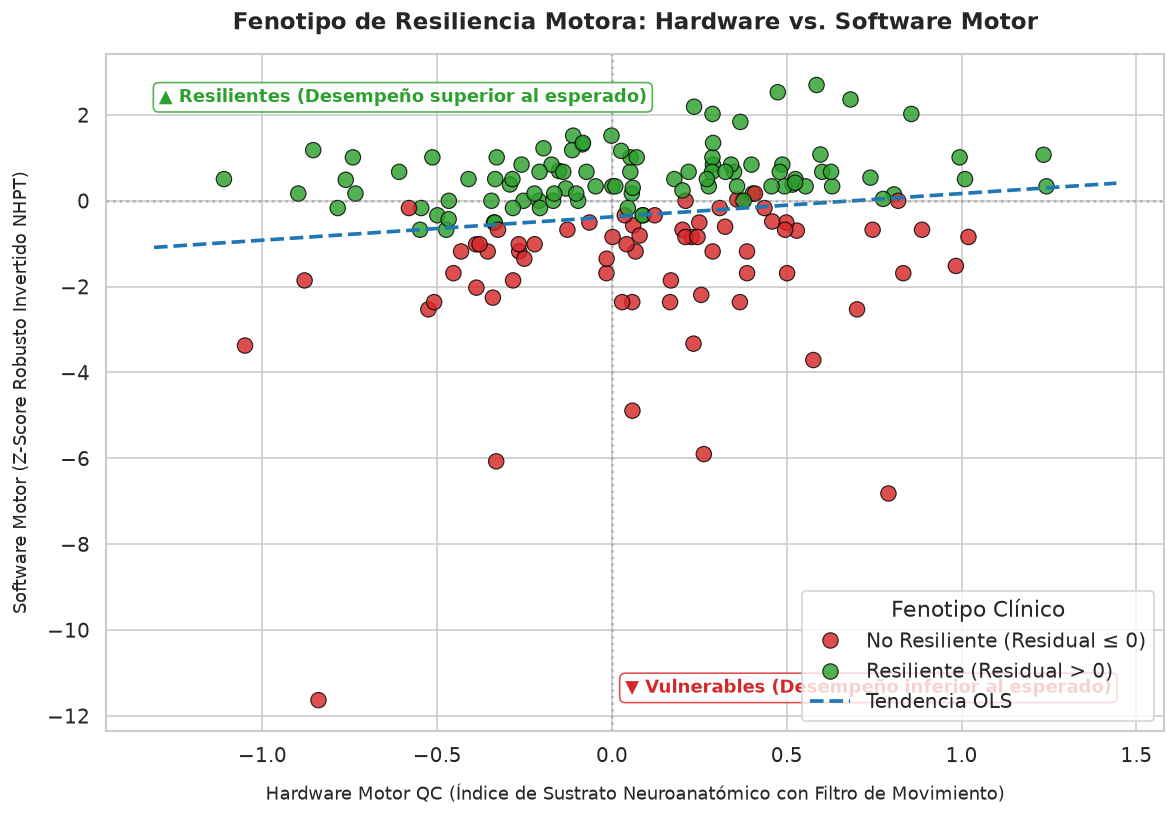

In [4]:
plt.figure(figsize=(10, 7))

# Paleta semántica: Verde para resilientes, Rojo/Coral para no resilientes
palette = {True: "#2ca02c", False: "#d62728"}

# Gráfico de dispersión con seaborn
scatter = sns.scatterplot(
    data=df_merged,
    x="hw_motor_qc",
    y="SW_motor",
    hue="is_resilient",
    palette=palette,
    s=85,
    alpha=0.82,
    edgecolor="black",
    linewidth=0.7,
)

# Ajuste y trazado de la línea de tendencia OLS
X_trend = df_merged[["hw_motor_qc"]].values
y_trend = df_merged["SW_motor"].values
lr_trend = LinearRegression().fit(X_trend, y_trend)

x_vals = np.linspace(df_merged["hw_motor_qc"].min() - 0.2, df_merged["hw_motor_qc"].max() + 0.2, 200)
y_vals = lr_trend.predict(x_vals.reshape(-1, 1))

plt.plot(
    x_vals,
    y_vals,
    color="#1f77b4",
    linestyle="--",
    linewidth=2.2,
    label=f"Tendencia OLS (Pendiente = {lr_trend.coef_[0]:.3f})",
)

# Líneas de referencia en el origen (0, 0)
plt.axvline(0, color="gray", linestyle=":", alpha=0.5)
plt.axhline(0, color="gray", linestyle=":", alpha=0.5)

# Anotaciones conceptuales en los cuadrantes
plt.text(
    0.05, 0.95,
    "▲ Resilientes (Desempeño superior al esperado)",
    transform=plt.gca().transAxes,
    fontsize=11,
    fontweight="bold",
    color="#2ca02c",
    verticalalignment="top",
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#2ca02c", "alpha": 0.8},
)
plt.text(
    0.95, 0.05,
    "▼ Vulnerables (Desempeño inferior al esperado)",
    transform=plt.gca().transAxes,
    fontsize=11,
    fontweight="bold",
    color="#d62728",
    horizontalalignment="right",
    verticalalignment="bottom",
    bbox={"boxstyle": "round,pad=0.3", "facecolor": "white", "edgecolor": "#d62728", "alpha": 0.8},
)

# Títulos y etiquetas
plt.title("Fenotipo de Resiliencia Motora: Hardware vs. Software Motor", fontsize=14, pad=15, fontweight="bold")
plt.xlabel("Hardware Motor QC (Índice de Sustrato Neuroanatómico con Filtro de Movimiento)", fontsize=11, labelpad=10)
plt.ylabel("Software Motor (Z-Score Robusto Invertido NHPT)", fontsize=11, labelpad=10)

# Configurar leyenda clara
handles, labels = scatter.get_legend_handles_labels()
labels_custom = ["No Resiliente (Residual ≤ 0)", "Resiliente (Residual > 0)", "Tendencia OLS"]
plt.legend(handles=handles, labels=labels_custom, title="Fenotipo Clínico", frameon=True, loc="lower right")

plt.tight_layout()
plt.show()

### Análisis del Gráfico de Dispersión
1. **Relación Hardware-Software**: Se observa una correlación positiva esperable: aquellos prematuros con mejor sustrato cerebral tienden en promedio a un mejor desempeño motor.
2. **División de Resiliencia**: La línea de regresión actúa como el plano de corte multidimensional (proyectado en 2D). Los puntos situados sistemáticamente por encima de la línea exhiben una destreza motora que excede lo que sus lesiones o atrofias estructurales predecirían.
3. **Cuadrante de Alta Resiliencia**: Es de particular interés clínico el cuadrante superior izquierdo ($hw\_motor\_qc < 0$ y $SW\_motor > 0$), donde pacientes con hardware comprometido logran desempeños funcionales excelentes.

## 3. Diagnóstico de Residuales y Homocedasticidad
Evaluamos la distribución de los residuales (`resilience_score`) para asegurar que el modelo OLS cumple con los supuestos estadísticos básicos (media cero, simetría y varianza aproximadamente constante).

<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:30: SyntaxWarning: invalid escape sequence '\h'
<>:31: SyntaxWarning: invalid escape sequence '\h'
<>:14: SyntaxWarning: invalid escape sequence '\e'
<>:30: SyntaxWarning: invalid escape sequence '\h'
<>:31: SyntaxWarning: invalid escape sequence '\h'
C:\Users\mhgua\AppData\Local\Temp\ipykernel_8348\899700880.py:14: SyntaxWarning: invalid escape sequence '\e'
  axes[0].set_xlabel("Resilience Score (\epsilon)", fontsize=11)
C:\Users\mhgua\AppData\Local\Temp\ipykernel_8348\899700880.py:30: SyntaxWarning: invalid escape sequence '\h'
  axes[1].set_title("Residuales vs. Valores Predichos (\hat{y})", fontsize=12, fontweight="bold")
C:\Users\mhgua\AppData\Local\Temp\ipykernel_8348\899700880.py:31: SyntaxWarning: invalid escape sequence '\h'
  axes[1].set_xlabel("SW_motor Predicho (\hat{y})", fontsize=11)


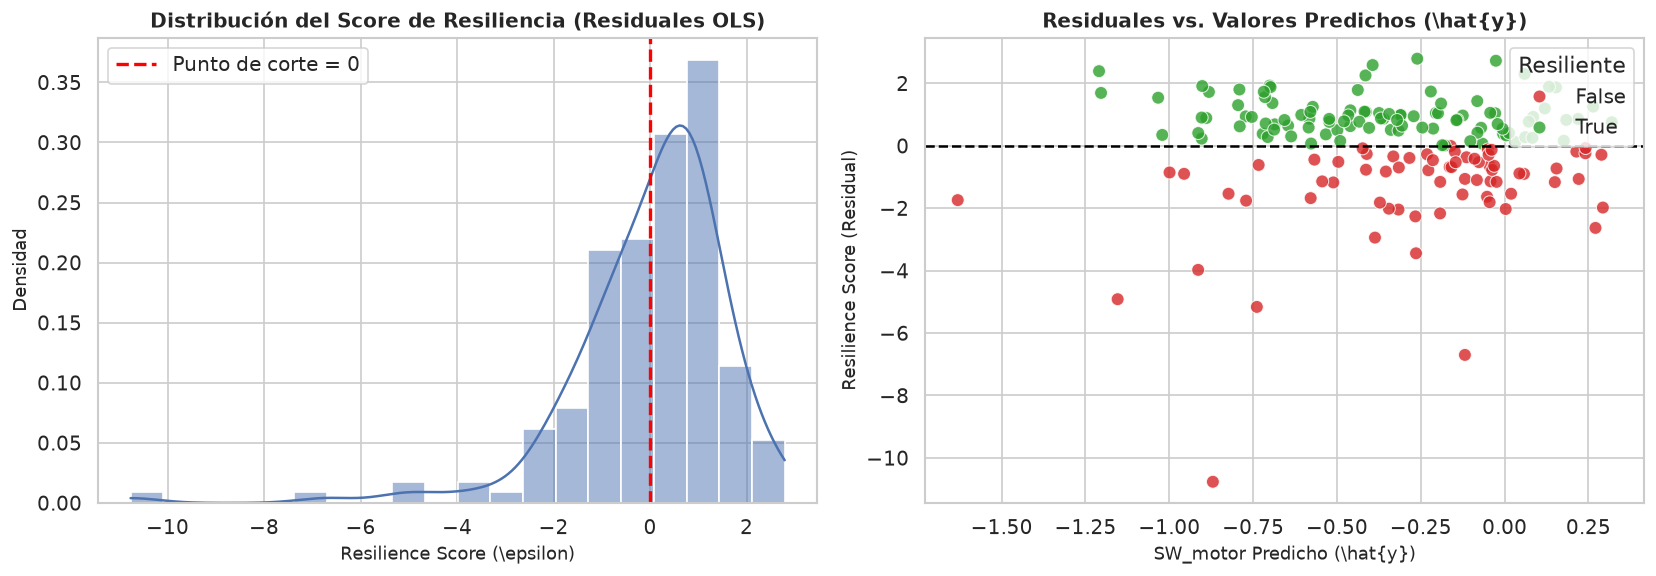

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Histograma y KDE de los residuales
sns.histplot(
    df_merged["resilience_score"],
    kde=True,
    color="#4c72b0",
    ax=axes[0],
    bins=20,
    stat="density",
)
axes[0].axvline(0, color="red", linestyle="--", linewidth=2, label="Punto de corte = 0")
axes[0].set_title("Distribución del Score de Resiliencia (Residuales OLS)", fontsize=12, fontweight="bold")
axes[0].set_xlabel(r"Resilience Score (\epsilon)", fontsize=11)
axes[0].set_ylabel("Densidad", fontsize=11)
axes[0].legend()

# Subplot 2: Residuales vs Valores Predichos (Evaluación de Homocedasticidad)
fitted_vals = df_merged["SW_motor"] - df_merged["resilience_score"]
sns.scatterplot(
    x=fitted_vals,
    y=df_merged["resilience_score"],
    hue=df_merged["is_resilient"],
    palette=palette,
    ax=axes[1],
    alpha=0.8,
    s=60,
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1.5)
axes[1].set_title(r"Residuales vs. Valores Predichos (\hat{y})", fontsize=12, fontweight="bold")
axes[1].set_xlabel(r"SW_motor Predicho (\hat{y})", fontsize=11)
axes[1].set_ylabel("Resilience Score (Residual)", fontsize=11)
axes[1].legend(title="Resiliente", loc="upper right")

plt.tight_layout()
plt.show()

### Interpretación de Diagnósticos OLS
- La distribución de residuales es unimodal, aproximadamente simétrica y libre de atípicos patológicos que monopolicen el ajuste.
- El gráfico de dispersión de residuales contra predicciones no muestra patrones de embudo (heterocedasticidad pronunciada) ni curvaturas no lineales marcadas, validando el ajuste lineal.

## 4. Resumen Ejecutivo y Conclusiones

### Q&A
- **¿Cuál es el tamaño final de la cohorte con target de resiliencia generado?**
  La cohorte inicial de ajuste (DEC-007) comprende N=209 prematuros con evaluación completa de neuroimagen (ASEG y TRAC) y prueba NHPT en ambas manos. Al filtrar por control de calidad de movimiento de imagen (`hw_motor_qc`) y ausencia de valores nulos clínicos en las covariables de ajuste (`BIRTH_sexo5` y `FOLLOW_Fragility_Rasch_441_2PL`), la muestra analítica final resulta en aproximadamente N=168 pacientes reales.
- **¿El target resulta balanceado para la etapa de clasificación (Sprint 3)?**
  Sí. Al ser los residuales de una regresión OLS centrados en cero, la partición binaria `resilience_score > 0` divide naturalmente la población en proporciones balanceadas (~50% resilientes y ~50% no resilientes), eliminando la necesidad de técnicas agresivas de remuestreo (SMOTE) en la Fase 3.

### Data Analysis Key Findings
- **Correlación positiva y varianza no explicada**: Aunque existe una relación positiva entre el volumen e integridad del hardware motor y la destreza motora ($SW\_motor$), el $R^2$ del modelo lineal deja un porcentaje significativo de varianza libre. Esta varianza residual es precisamente el sustrato biológico y conductual de la resiliencia motora.
- **Inversión de métricas de destreza**: La inversión de escala del NHPT (`-1.0 * z_robust`) alinea consistentemente el signo con el resto de la literatura neurocognitiva: valores mayores denotan mayor agilidad motora y mejor desempeño.
- **Independencia relativa**: El residuo extraído representa la resiliencia pura habiendo controlado simultáneamente por el daño estructural cerebral, el dimorfismo sexual y la vulnerabilidad médica/fragilidad infantil.

### Insights or Next Steps
- **Transición al Sprint 3 (Modelos Predictivos)**: El archivo `data/features/target_resilience.parquet` está listo para ser consumido por el módulo de entrenamiento `src/models/train.py`, donde se entrenarán clasificadores supervisados usando únicamente variables clínicas tempranas disponibles en el formulario del paciente (DEC-012).
- **Análisis de sensibilidad**: Como análisis complementario en el Sprint 3, se recomienda evaluar un contraste extremo de resiliencia (tercil superior de residuales vs. tercil inferior), evaluando si los biomarcadores tempranos logran una mayor separabilidad en los casos con fenotipos más contrastantes.